## 13.5 2012 Federal Election Commission Database


- Notebook này dựa trên các đoạn code được trích xuất từ tài liệu PDF về phân tích dữ liệu đóng góp cho chiến dịch bầu cử năm 2012 từ Ủy ban Bầu cử Liên bang (FEC). Chúng ta sẽ đi qua từng phần một cách chi tiết, giải thích ý nghĩa của từng dòng code, công cụ sử dụng (chủ yếu là Pandas và NumPy), và cách chúng góp phần vào phân tích tổng thể.

- Lưu ý:
    - Chúng ta giả sử đã có file dữ liệu P00000001-ALL.csv trong thư mục datasets/fec/. Nếu không, có thể tải từ kho dữ liệu của sách (ví dụ: từ GitHub của "Python for Data Analysis").
    - Các thư viện cần thiết: Pandas, NumPy, Matplotlib (cho vẽ biểu đồ).

### 1. Tải Dữ Liệu Và Kiểm Tra Thông Tin Cơ Bản

- Phần này tải file CSV chứa dữ liệu đóng góp bầu cử năm 2012. Dữ liệu bao gồm thông tin như tên ứng cử viên, người đóng góp, số tiền, nghề nghiệp, v.v. Chúng ta sử dụng pd.read_csv để tải và info() để xem cấu trúc DataFrame.

In [ ]:
import pandas as pd # Import Pandas để xử lý dữ liệu bảng

In [ ]:
# Tải file CSV với tùy chọn low_memory=False để tránh cảnh báo về kiểu dữ liệu lớn
fec = pd.read_csv("datasets/fec/P00000001-ALL.csv", low_memory=False)

# Hiển thị thông tin tổng quát về DataFrame: số dòng, cột, kiểu dữ liệu, và bộ nhớ sử dụng
fec.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1001731 entries, 0 to 1001730
Data columns (total 16 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   cmte_id            1001731 non-null  object 
 1   cand_id            1001731 non-null  object 
 2   cand_nm            1001731 non-null  object 
 3   contbr_nm          1001731 non-null  object 
 4   contbr_city        1001712 non-null  object 
 5   contbr_st          1001727 non-null  object 
 6   contbr_zip         1001620 non-null  object 
 7   contbr_employer    988002 non-null   object 
 8   contbr_occupation  993301 non-null   object 
 9   contb_receipt_amt  1001731 non-null  float64
 10  contb_receipt_dt   1001731 non-null  object 
 11  receipt_desc       14166 non-null    object 
 12  memo_cd            92482 non-null    object 
 13  memo_text          97770 non-null    object 
 14  form_tp            1001731 non-null  object 
 15  file_num           1001731 non-n

- Giải thích chi tiết:
    - import pandas as pd: Import thư viện Pandas và gán biệt danh pd để gọi ngắn gọn.

    - pd.read_csv("datasets/fec/P00000001-ALL.csv", low_memory=False): Đọc file CSV vào DataFrame fec. Tùy chọn low_memory=False ngăn Pandas đoán kiểu dữ liệu từng phần (hữu ích cho file lớn ~150MB). Mặc định là "True" khi đó có thể gây cảnh báo dtype nếu cột chứa cả số và chữ. Còn khi là "False" đọc an toàn hơn, đảm bảo pandas xác định đúng kiểu dữ liệu

    - fec.info(): In ra tóm tắt DataFrame, bao gồm số lượng giá trị không null, kiểu dữ liệu (ví dụ: object cho chuỗi, float64 cho số thực), và bộ nhớ. Điều này giúp kiểm tra dữ liệu có bị thiếu không.

- Mô tả dữ liệu

    | #  | Column name         | Non-Null Count | Dtype   | Giải thích                                              |
    | -- | ------------------- | -------------- | ------- | ------------------------------------------------------- |
    | 0  | `cmte_id`           | 1,001,731      | object  | ID của ủy ban gây quỹ (committee ID)                    |
    | 1  | `cand_id`           | 1,001,731      | object  | ID của ứng cử viên (candidate ID)                       |
    | 2  | `cand_nm`           | 1,001,731      | object  | Tên ứng cử viên                                         |
    | 3  | `contbr_nm`         | 1,001,731      | object  | Tên người đóng góp (contributor)                        |
    | 4  | `contbr_city`       | 1,001,712      | object  | Thành phố của người đóng góp *(19 giá trị bị thiếu)*    |
    | 5  | `contbr_st`         | 1,001,727      | object  | Bang (State) *(4 giá trị bị thiếu)*                     |
    | 6  | `contbr_zip`        | 1,001,620      | object  | Mã ZIP *(111 giá trị bị thiếu)*                         |
    | 7  | `contbr_employer`   | 988,002        | object  | Tên công ty / đơn vị công tác *(hơn 13 nghìn bị thiếu)* |
    | 8  | `contbr_occupation` | 993,301        | object  | Nghề nghiệp *(~7 nghìn bị thiếu)*                       |
    | 9  | `contb_receipt_amt` | 1,001,731      | float64 | **Số tiền đóng góp** (cột quan trọng nhất)              |
    | 10 | `contb_receipt_dt`  | 1,001,731      | object  | Ngày đóng góp (chưa được chuyển sang kiểu `datetime`)   |
    | 11 | `receipt_desc`      | 14,166         | object  | Mô tả giao dịch (nhiều ô bị trống)                      |
    | 12 | `memo_cd`           | 92,482         | object  | Mã ghi chú (ít dữ liệu)                                 |
    | 13 | `memo_text`         | 97,770         | object  | Nội dung ghi chú                                        |
    | 14 | `form_tp`           | 1,001,731      | object  | Loại biểu mẫu                                           |
    | 15 | `file_num`          | 1,001,731      | int64   | Mã số tệp khai báo                                      |

    - Có này có 1,001,731 dòng, 16 cột trong bảng dữ liệu
    
    - float64: có 1 cột (số thực — contb_receipt_amt)

    - int64: có 1 cột (file_num)

    - object: có 14 cột (chuỗi ký tự — thường là tên, địa chỉ, mô tả,...)

    - Chiếm khoảng 122 MB trong bộ nhớ

    - Một số cột có giá trị bị thiếu (đặc biệt employer, occupation, receipt_desc, memo_cd, memo_text)


### 2. Truy Xuất Một Bản Ghi Mẫu
Để xem một ví dụ cụ thể về dữ liệu, lấy một dòng từ DataFrame.

In [ ]:
# Lấy dòng thứ 123456 (chỉ số bắt đầu từ 0) và hiển thị dưới dạng Series
fec.iloc[123456]

cmte_id                             C00431445
cand_id                             P80003338
cand_nm                         Obama, Barack
contbr_nm                         ELLMAN, IRA
contbr_city                             TEMPE
contbr_st                                  AZ
contbr_zip                          852816719
contbr_employer      ARIZONA STATE UNIVERSITY
contbr_occupation                   PROFESSOR
contb_receipt_amt                        50.0
contb_receipt_dt                    01-DEC-11
receipt_desc                              NaN
memo_cd                                   NaN
memo_text                                 NaN
form_tp                                 SA17A
file_num                               772372
Name: 123456, dtype: object

- Giải thích chi tiết:
    - fec.iloc[123456]: Sử dụng iloc (index location) để truy cập dòng theo vị trí số. Kết quả là một Series hiển thị chi tiết một khoản đóng góp (ví dụ: ứng cử viên Obama, người đóng góp Ira Ellman, số tiền 50 USD, v.v.).

    - Ý nghĩa: Giúp kiểm tra dữ liệu thực tế, xác nhận cấu trúc (như cột cand_nm cho tên ứng cử viên, contb_receipt_amt cho số tiền).

### 3. Lấy Danh Sách Ứng Cử Viên Duy Nhất
Phần này lấy danh sách các ứng cử viên duy nhất từ cột cand_nm.

In [ ]:
# Lấy các giá trị duy nhất từ cột 'cand_nm' dưới dạng mảng NumPy
unique_cands = fec["cand_nm"].unique()

# Hiển thị toàn bộ mảng
unique_cands

array(['Bachmann, Michelle', 'Romney, Mitt', 'Obama, Barack',
       "Roemer, Charles E. 'Buddy' III", 'Pawlenty, Timothy',
       'Johnson, Gary Earl', 'Paul, Ron', 'Santorum, Rick',
       'Cain, Herman', 'Gingrich, Newt', 'McCotter, Thaddeus G',
       'Huntsman, Jon', 'Perry, Rick'], dtype=object)

In [ ]:
# Hiển thị phần tử thứ 3 (chỉ số 2) trong mảng
unique_cands[2]

'Obama, Barack'

- Giải thích chi tiết:
    - fec["cand_nm"].unique(): Truy cập cột cand_nm (tên ứng cử viên) như một Series, sau đó dùng unique() để loại bỏ trùng lặp và trả về mảng các giá trị duy nhất.

    - unique_cands: Lưu kết quả vào biến để sử dụng sau.

    - unique_cands[2]: Truy cập phần tử cụ thể (ví dụ: 'Obama, Barack').
    
    -Ý nghĩa: Xác định tất cả ứng cử viên trong dữ liệu, hữu ích để ánh xạ đảng phái sau này.

### 4. Ánh Xạ Đảng Phái Cho Ứng Cử Viên
Vì dữ liệu không có cột đảng phái, chúng ta tạo một từ điển để ánh xạ và thêm cột mới.

In [ ]:
# Tạo từ điển ánh xạ tên ứng cử viên sang đảng phái
parties = {"Bachmann, Michelle": "Republican",
           "Cain, Herman": "Republican",
           "Gingrich, Newt": "Republican",
           "Huntsman, Jon": "Republican",
           "Johnson, Gary Earl": "Republican",
           "McCotter, Thaddeus G": "Republican",
           "Obama, Barack": "Democrat",
           "Paul, Ron": "Republican",
           "Pawlenty, Timothy": "Republican",
           "Perry, Rick": "Republican",
           "Roemer, Charles E. 'Buddy' III": "Republican",
           "Romney, Mitt": "Republican",
           "Santorum, Rick": "Republican"}

In [ ]:
# Hiển thị 5 dòng từ 123456 đến 123460 trong cột 'cand_nm'
fec["cand_nm"][123456:123461]

123456    Obama, Barack
123457    Obama, Barack
123458    Obama, Barack
123459    Obama, Barack
123460    Obama, Barack
Name: cand_nm, dtype: object

In [ ]:
# Áp dụng ánh xạ parties lên các dòng đó và hiển thị đảng phái
fec["cand_nm"][123456:123461].map(parties)


123456    Democrat
123457    Democrat
123458    Democrat
123459    Democrat
123460    Democrat
Name: cand_nm, dtype: object

- .map() dùng để chuyển đổi (mapping) từng giá trị trong Series
dựa trên từ điển parties đã định nghĩa trước đó.

- Nếu tên ứng cử viên có trong parties, pandas sẽ trả về đảng phái tương ứng.
Nếu không có, nó sẽ trả về NaN.

- Có thể sử dụng cú pháp: **fec["cand_nm"].map(parties)[123456:123461]** cho kết quả vẫn như nhau, nhưng tốn thời gian và bộ nhớ hơn (vì map 1 triệu dòng thay vì 5 dòng). Vì khi đó sẽ áp dụng map() lên toàn bộ 1 triệu dòng còn cách được sử dụng trong code cắt ra 5 dòng cần kiểm tra trước rồi mới áp dụng map()

In [ ]:
# Thêm cột 'party' mới vào DataFrame bằng cách ánh xạ toàn bộ cột 'cand_nm'
fec["party"] = fec["cand_nm"].map(parties)

In [ ]:
fec.head()  # Hiển thị 5 dòng đầu tiên của DataFrame để kiểm tra cột mới thêm

,cmte_id,cand_id,cand_nm,contbr_nm,contbr_city,contbr_st,contbr_zip,contbr_employer,contbr_occupation,contb_receipt_amt,contb_receipt_dt,receipt_desc,memo_cd,memo_text,form_tp,file_num,party
0,C00410118,P20002978,"Bachmann, Michelle","HARVEY, WILLIAM",MOBILE,AL,366010290,RETIRED,RETIRED,250.0,20-JUN-11,NaN,NaN,NaN,SA17A,736166,Republican
1,C00410118,P20002978,"Bachmann, Michelle","HARVEY, WILLIAM",MOBILE,AL,366010290,RETIRED,RETIRED,50.0,23-JUN-11,NaN,NaN,NaN,SA17A,736166,Republican
2,C00410118,P20002978,"Bachmann, Michelle","SMITH, LANIER",LANETT,AL,368633403,INFORMATION REQUESTED,INFORMATION REQUESTED,250.0,05-JUL-11,NaN,NaN,NaN,SA17A,749073,Republican
3,C00410118,P20002978,"Bachmann, Michelle","BLEVINS, DARONDA",PIGGOTT,AR,724548253,NONE,RETIRED,250.0,01-AUG-11,NaN,NaN,NaN,SA17A,749073,Republican
4,C00410118,P20002978,"Bachmann, Michelle","WARDENBURG, HAROLD",HOT SPRINGS NATION,AR,719016467,NONE,RETIRED,300.0,20-JUN-11,NaN,NaN,NaN,SA17A,736166,Republican


In [ ]:
fec.info()  # Kiểm tra lại thông tin DataFrame sau khi thêm cột mới

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1001731 entries, 0 to 1001730
Data columns (total 17 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   cmte_id            1001731 non-null  object 
 1   cand_id            1001731 non-null  object 
 2   cand_nm            1001731 non-null  object 
 3   contbr_nm          1001731 non-null  object 
 4   contbr_city        1001712 non-null  object 
 5   contbr_st          1001727 non-null  object 
 6   contbr_zip         1001620 non-null  object 
 7   contbr_employer    988002 non-null   object 
 8   contbr_occupation  993301 non-null   object 
 9   contb_receipt_amt  1001731 non-null  float64
 10  contb_receipt_dt   1001731 non-null  object 
 11  receipt_desc       14166 non-null    object 
 12  memo_cd            92482 non-null    object 
 13  memo_text          97770 non-null    object 
 14  form_tp            1001731 non-null  object 
 15  file_num           1001731 non-n

- Lúc này cột "party" đã được thêm vào cuối

In [ ]:
# Đếm số lượng giá trị trong cột 'party' (Democrat và Republican)
fec["party"].value_counts()

party
Democrat      593746
Republican    407985
Name: count, dtype: int64

In [ ]:
(fec["party"].isnull().sum())# Kiểm tra số lượng giá trị thiếu ở cột 'party'

np.int64(0)

In [ ]:
fec.info()  # Kiểm tra lại thông tin DataFrame sau khi thêm cột mới

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1001731 entries, 0 to 1001730
Data columns (total 17 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   cmte_id            1001731 non-null  object 
 1   cand_id            1001731 non-null  object 
 2   cand_nm            1001731 non-null  object 
 3   contbr_nm          1001731 non-null  object 
 4   contbr_city        1001712 non-null  object 
 5   contbr_st          1001727 non-null  object 
 6   contbr_zip         1001620 non-null  object 
 7   contbr_employer    988002 non-null   object 
 8   contbr_occupation  993301 non-null   object 
 9   contb_receipt_amt  1001731 non-null  float64
 10  contb_receipt_dt   1001731 non-null  object 
 11  receipt_desc       14166 non-null    object 
 12  memo_cd            92482 non-null    object 
 13  memo_text          97770 non-null    object 
 14  form_tp            1001731 non-null  object 
 15  file_num           1001731 non-n

<Axes: >

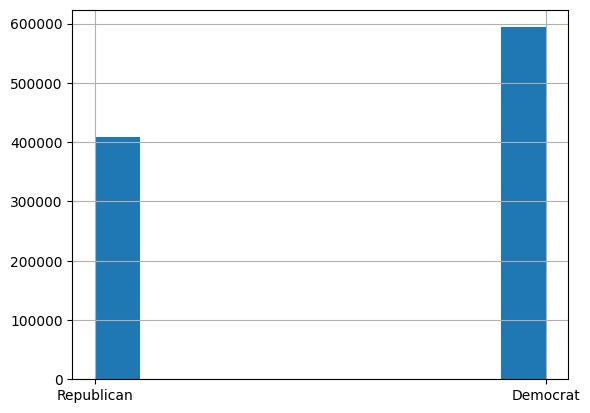

In [ ]:
fec["party"].hist() # Vẽ biểu đồ histogram cho cột 'party'

- Giải thích chi tiết:
    - parties = {...}: Từ điển (dictionary) với key là tên ứng cử viên, value là đảng phái. Lưu ý: Giả sử Gary Johnson là Republican dù sau này ông chuyển đảng.

    - fec["cand_nm"][123456:123461]: Lấy slice (lát cắt) của Series để kiểm tra.
    .map(parties): Phương thức map của Series thay thế giá trị dựa trên từ điển. Nếu không khớp, trả về NaN (nhưng ở đây tất cả đều khớp).

    - fec["party"] = ...: Thêm cột mới vào DataFrame.

    - fec["party"].value_counts(): Đếm tần suất từng đảng phái (ví dụ: Democrat nhiều hơn Republican).
    
    -Ý nghĩa: Thêm thông tin đảng phái để phân tích theo nhóm sau này.

### 5. Lọc Dữ Liệu Đóng Góp Dương
Dữ liệu có cả đóng góp và hoàn tiền (âm). Chúng ta lọc chỉ giữ đóng góp dương và tập trung vào Obama & Romney.

In [ ]:
# Kiểm tra contributions âm/dương
(fec["contb_receipt_amt"] > 0).value_counts()

contb_receipt_amt
True     991475
False     10256
Name: count, dtype: int64

In [ ]:
print(f"Số lượng giá trị thiếu ở cột đóng góp: {fec["contb_receipt_amt"].isnull().sum()}")
fec.isnull().sum() # Kiểm tra số lượng giá trị thiếu ở mỗi cột

Số lượng giá trị thiếu ở cột đóng góp: 0


cmte_id                   0
cand_id                   0
cand_nm                   0
contbr_nm                 0
contbr_city              19
contbr_st                 4
contbr_zip              111
contbr_employer       13729
contbr_occupation      8430
contb_receipt_amt         0
contb_receipt_dt          0
receipt_desc         987565
memo_cd              909249
memo_text            903961
form_tp                   0
file_num                  0
party                     0
dtype: int64

In [ ]:
# Lọc chỉ lấy contributions dương
fec = fec[fec["contb_receipt_amt"] > 0] # Lọc lại DataFrame để chỉ giữ lại các dòng có giá trị đóng góp dương

fec.info() # Kiểm tra lại thông tin DataFrame sau khi lọc

<class 'pandas.core.frame.DataFrame'>
Index: 991475 entries, 0 to 1001730
Data columns (total 17 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   cmte_id            991475 non-null  object 
 1   cand_id            991475 non-null  object 
 2   cand_nm            991475 non-null  object 
 3   contbr_nm          991475 non-null  object 
 4   contbr_city        991457 non-null  object 
 5   contbr_st          991471 non-null  object 
 6   contbr_zip         991373 non-null  object 
 7   contbr_employer    983833 non-null  object 
 8   contbr_occupation  989133 non-null  object 
 9   contb_receipt_amt  991475 non-null  float64
 10  contb_receipt_dt   991475 non-null  object 
 11  receipt_desc       5219 non-null    object 
 12  memo_cd            89461 non-null   object 
 13  memo_text          94274 non-null   object 
 14  form_tp            991475 non-null  object 
 15  file_num           991475 non-null  int64  
 16  party 

- Sau khi thực hiện bước lọc các đóng góp các giá trị dương từ Dataframe ban đầu là 1001731 dòng thành 991475 dòng => đã loại bỏ 10256 các dòng có đóng góp âm (hoàn tiền) hoặc bằng 0

In [ ]:
# Lọc chỉ lấy Obama và Romney
fec_mrbo = fec[fec["cand_nm"].isin(["Obama, Barack", "Romney, Mitt"])] # Lọc lại DataFrame để chỉ giữ lại các dòng ứng cử viên là Obama hoặc Romney

- Tạo một DataFrame mới chỉ chứa các dòng là ứng viên Obama hoặc Romney

In [ ]:
fec_mrbo.info() # Kiểm tra lại thông tin DataFrame sau khi lọc

<class 'pandas.core.frame.DataFrame'>
Index: 694282 entries, 411 to 701385
Data columns (total 17 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   cmte_id            694282 non-null  object 
 1   cand_id            694282 non-null  object 
 2   cand_nm            694282 non-null  object 
 3   contbr_nm          694282 non-null  object 
 4   contbr_city        694275 non-null  object 
 5   contbr_st          694278 non-null  object 
 6   contbr_zip         694234 non-null  object 
 7   contbr_employer    693607 non-null  object 
 8   contbr_occupation  693524 non-null  object 
 9   contb_receipt_amt  694282 non-null  float64
 10  contb_receipt_dt   694282 non-null  object 
 11  receipt_desc       2345 non-null    object 
 12  memo_cd            87387 non-null   object 
 13  memo_text          90672 non-null   object 
 14  form_tp            694282 non-null  object 
 15  file_num           694282 non-null  int64  
 16  party

In [ ]:
fec_mrbo.head() # Hiển thị 5 dòng đầu tiên của DataFrame đã lọc

,cmte_id,cand_id,cand_nm,contbr_nm,contbr_city,contbr_st,contbr_zip,contbr_employer,contbr_occupation,contb_receipt_amt,contb_receipt_dt,receipt_desc,memo_cd,memo_text,form_tp,file_num,party
411,C00431171,P80003353,"Romney, Mitt","ELDERBAUM, WILLIAM",DPO,AA,340230183,US GOVERNMENT,FOREIGN SERVICE OFFICER,25.0,01-FEB-12,NaN,NaN,NaN,SA17A,780124,Republican
412,C00431171,P80003353,"Romney, Mitt","ELDERBAUM, WILLIAM",DPO,AA,340230183,US GOVERNMENT,FOREIGN SERVICE OFFICER,110.0,01-FEB-12,NaN,NaN,NaN,SA17A,780124,Republican
413,C00431171,P80003353,"Romney, Mitt","CARLSEN, RICHARD",APO,AE,091280020,DEFENSE INTELLIGENCE AGENCY,INTELLIGENCE ANALYST,250.0,13-APR-12,NaN,NaN,NaN,SA17A,785689,Republican
414,C00431171,P80003353,"Romney, Mitt","DELUCA, PIERRE",APO,AE,091280005,CISCO,ENGINEER,30.0,21-AUG-11,NaN,NaN,NaN,SA17A,760261,Republican
415,C00431171,P80003353,"Romney, Mitt","SARGENT, MICHAEL",APO,AE,090120092,RAYTHEON TECHNICAL SERVICES CORP,COMPUTER SYSTEMS ENGINEER,100.0,07-MAR-12,NaN,NaN,NaN,SA17A,780128,Republican


In [ ]:
fec_mrbo.tail() # Hiển thị 5 dòng cuối cùng của DataFrame đã lọc

,cmte_id,cand_id,cand_nm,contbr_nm,contbr_city,contbr_st,contbr_zip,contbr_employer,contbr_occupation,contb_receipt_amt,contb_receipt_dt,receipt_desc,memo_cd,memo_text,form_tp,file_num,party
701381,C00431445,P80003338,"Obama, Barack","MOUNTS, ROBERT",APO,ZZ,962043077,HQ USFK (FKDC-SA),GS-15 INTERNATIONAL RELATIONS OFFICER,25.0,26-FEB-12,NaN,NaN,NaN,SA17A,787803,Democrat
701382,C00431445,P80003338,"Obama, Barack","TAITANO, TYRONE",HAGATNA,ZZ,969323373,NOT EMPLOYED,RETIRED,250.0,20-JAN-12,NaN,NaN,NaN,SA17A,775668,Democrat
701383,C00431445,P80003338,"Obama, Barack","TUCKER, PAMELA",APO,ZZ,963190030,DODEA,EDUCATOR,3.0,20-JAN-12,NaN,NaN,NaN,SA17A,775668,Democrat
701384,C00431445,P80003338,"Obama, Barack","MOUNTS, ROBERT",APO,ZZ,962043077,HQ USFK (FKDC-SA),GS-15 INTERNATIONAL RELATIONS OFFICER,25.0,26-APR-12,NaN,NaN,NaN,SA17A,785239,Democrat
701385,C00431445,P80003338,"Obama, Barack","NEAL, AMBER",APO,ZZ,091022065,THE DEPARTMENT OF DEFENSE EDUCATION AC,TEACHER,135.0,04-SEP-11,NaN,X,* OBAMA VICTORY FUND 2012,SA18,756218,Democrat


- Giải thích chi tiết:
    - (fec["contb_receipt_amt"] > 0).value_counts(): Tạo Series boolean (True nếu >0), sau đó đếm True/False để kiểm tra tỷ lệ đóng góp dương/âm.

    - fec = fec[... > 0]: Lọc DataFrame bằng boolean indexing, giữ nguyên biến fec.

    - fec["cand_nm"].isin([...]): Kiểm tra xem tên ứng cử viên có trong list không, trả về boolean Series.
        - fec["cand_nm"] truy cập vào cột tên ứng cử viên (candidate name),
        - .isin(["Obama, Barack", "Romney, Mitt"]) Kiểm tra từng dòng trong cột cand_nm xem tên ứng cử viên có nằm trong danh sách [“Obama, Barack”, “Romney, Mitt”] hay không. Kết quả là một mảng Boolean (True/False) có cùng số dòng với DataFrame.
        - fec[...] Đây là cú pháp lọc hàng (row filtering) trong pandas. Nó sẽ chỉ giữ lại những dòng mà điều kiện trong ngoặc [] là True.

    -Ý nghĩa: Làm sạch dữ liệu để tập trung vào đóng góp thực tế và hai ứng cử viên chính.

### 6. Thống Kê Nghề Nghiệp
Đếm top 10 nghề nghiệp phổ biến nhất.

In [ ]:
# Đếm tần suất nghề nghiệp và lấy top 10
fec["contbr_occupation"].value_counts()[:10]

contbr_occupation
RETIRED                                   233990
INFORMATION REQUESTED                      35107
ATTORNEY                                   34286
HOMEMAKER                                  29931
PHYSICIAN                                  23432
INFORMATION REQUESTED PER BEST EFFORTS     21138
ENGINEER                                   14334
TEACHER                                    13990
CONSULTANT                                 13273
PROFESSOR                                  12555
Name: count, dtype: int64

- Giải thích chi tiết:
    - fec["contbr_occupation"].value_counts(): Đếm số lần xuất hiện từng giá trị trong cột nghề nghiệp, trả về Series sắp xếp giảm dần.

    - [:10]: Lấy 10 phần tử đầu.
    
    -Ý nghĩa: Xem nghề nghiệp nào đóng góp nhiều nhất (ví dụ: RETIRED là top).

### 7. Làm Sạch Dữ Liệu Nghề Nghiệp Và Nhà Tuyển Dụng
Chuẩn hóa các giá trị lặp hoặc tương tự bằng từ điển và hàm.

In [ ]:
fec.head()  # Hiển thị 5 dòng đầu tiên của DataFrame trước khi làm sạch

,cmte_id,cand_id,cand_nm,contbr_nm,contbr_city,contbr_st,contbr_zip,contbr_employer,contbr_occupation,contb_receipt_amt,contb_receipt_dt,receipt_desc,memo_cd,memo_text,form_tp,file_num,party
0,C00410118,P20002978,"Bachmann, Michelle","HARVEY, WILLIAM",MOBILE,AL,366010290,RETIRED,RETIRED,250.0,20-JUN-11,NaN,NaN,NaN,SA17A,736166,Republican
1,C00410118,P20002978,"Bachmann, Michelle","HARVEY, WILLIAM",MOBILE,AL,366010290,RETIRED,RETIRED,50.0,23-JUN-11,NaN,NaN,NaN,SA17A,736166,Republican
2,C00410118,P20002978,"Bachmann, Michelle","SMITH, LANIER",LANETT,AL,368633403,INFORMATION REQUESTED,INFORMATION REQUESTED,250.0,05-JUL-11,NaN,NaN,NaN,SA17A,749073,Republican
3,C00410118,P20002978,"Bachmann, Michelle","BLEVINS, DARONDA",PIGGOTT,AR,724548253,NONE,RETIRED,250.0,01-AUG-11,NaN,NaN,NaN,SA17A,749073,Republican
4,C00410118,P20002978,"Bachmann, Michelle","WARDENBURG, HAROLD",HOT SPRINGS NATION,AR,719016467,NONE,RETIRED,300.0,20-JUN-11,NaN,NaN,NaN,SA17A,736166,Republican


In [ ]:
fec.tail()  # Hiển thị 5 dòng cuối cùng của DataFrame trước khi làm sạch

,cmte_id,cand_id,cand_nm,contbr_nm,contbr_city,contbr_st,contbr_zip,contbr_employer,contbr_occupation,contb_receipt_amt,contb_receipt_dt,receipt_desc,memo_cd,memo_text,form_tp,file_num,party
1001726,C00500587,P20003281,"Perry, Rick","GORMAN, CHRIS D. MR.",INFO REQUESTED,XX,99999,INFORMATION REQUESTED PER BEST EFFORTS,INFORMATION REQUESTED PER BEST EFFORTS,5000.0,29-SEP-11,REATTRIBUTION / REDESIGNATION REQUESTED (AUTOM...,NaN,REATTRIBUTION / REDESIGNATION REQUESTED (AUTOM...,SA17A,751678,Republican
1001727,C00500587,P20003281,"Perry, Rick","DUFFY, DAVID A. MR.",INFO REQUESTED,XX,99999,DUFFY EQUIPMENT COMPANY INC.,BUSINESS OWNER,2500.0,30-SEP-11,NaN,NaN,NaN,SA17A,751678,Republican
1001728,C00500587,P20003281,"Perry, Rick","GRANE, BRYAN F. MR.",INFO REQUESTED,XX,99999,INFORMATION REQUESTED PER BEST EFFORTS,INFORMATION REQUESTED PER BEST EFFORTS,500.0,29-SEP-11,NaN,NaN,NaN,SA17A,751678,Republican
1001729,C00500587,P20003281,"Perry, Rick","TOLBERT, DARYL MR.",INFO REQUESTED,XX,99999,T.A.C.C.,LONGWALL MAINTENANCE FOREMAN,500.0,30-SEP-11,NaN,NaN,NaN,SA17A,751678,Republican
1001730,C00500587,P20003281,"Perry, Rick","ANDERSON, MARILEE MRS.",INFO REQUESTED,XX,99999,INFORMATION REQUESTED PER BEST EFFORTS,INFORMATION REQUESTED PER BEST EFFORTS,2500.0,31-AUG-11,NaN,NaN,NaN,SA17A,751678,Republican


In [ ]:
# Từ điển ánh xạ để chuẩn hóa nghề nghiệp
occ_mapping = {
    "INFORMATION REQUESTED PER BEST EFFORTS": "NOT PROVIDED",
    "INFORMATION REQUESTED": "NOT PROVIDED",
    "INFORMATION REQUESTED (BEST EFFORTS)": "NOT PROVIDED",
    "C.E.O.": "CEO"
}

In [ ]:
# Hàm lấy giá trị từ mapping, nếu không có thì giữ nguyên
def get_occ(x):
    return occ_mapping.get(x, x) #

In [ ]:
fec["contbr_occupation"].value_counts()[:10] # Hiển thị tần suất nghề nghiệp trước khi làm sạch

contbr_occupation
RETIRED                                   233990
INFORMATION REQUESTED                      35107
ATTORNEY                                   34286
HOMEMAKER                                  29931
PHYSICIAN                                  23432
INFORMATION REQUESTED PER BEST EFFORTS     21138
ENGINEER                                   14334
TEACHER                                    13990
CONSULTANT                                 13273
PROFESSOR                                  12555
Name: count, dtype: int64

In [ ]:
# Áp dụng hàm lên toàn bộ cột
fec["contbr_occupation"] = fec["contbr_occupation"].map(get_occ)

# Kiểm tra lại tần suất nghề nghiệp sau khi làm sạch
fec["contbr_occupation"].value_counts()[:10]

contbr_occupation
RETIRED         233990
NOT PROVIDED     57151
ATTORNEY         34286
HOMEMAKER        29931
PHYSICIAN        23432
ENGINEER         14334
TEACHER          13990
CONSULTANT       13273
PROFESSOR        12555
NOT EMPLOYED      9828
Name: count, dtype: int64

In [ ]:
# Từ điển ánh xạ để chuẩn hóa nhà tuyển dụng
emp_mapping = {
    "INFORMATION REQUESTED PER BEST EFFORTS": "NOT PROVIDED",
    "INFORMATION REQUESTED": "NOT PROVIDED",
    "SELF": "SELF-EMPLOYED",
    "SELF EMPLOYED": "SELF-EMPLOYED",
}

In [ ]:
# Hàm lấy giá trị từ mapping, nếu không có thì giữ nguyên
def get_emp(x):
    return emp_mapping.get(x, x)

In [ ]:
fec["contbr_employer"].value_counts()[:10] # Hiển thị tần suất nhà tuyển dụng trước khi làm sạch

contbr_employer
RETIRED                                   206675
SELF-EMPLOYED                              94505
NOT EMPLOYED                               45877
INFORMATION REQUESTED                      36135
SELF                                       24385
INFORMATION REQUESTED PER BEST EFFORTS     22260
NONE                                       19929
HOMEMAKER                                  18269
SELF EMPLOYED                               6274
REQUESTED                                   4233
Name: count, dtype: int64

In [ ]:
# Áp dụng hàm lên toàn bộ cột
fec["contbr_employer"] = fec["contbr_employer"].map(get_emp)

# Kiểm tra lại tần suất nhà tuyển dụng sau khi làm sạch
fec["contbr_employer"].value_counts()[:10]

contbr_employer
RETIRED          206675
SELF-EMPLOYED    125164
NOT PROVIDED      58396
NOT EMPLOYED      45877
NONE              19929
HOMEMAKER         18269
REQUESTED          4233
UNEMPLOYED         2514
US ARMY            1817
STUDENT            1786
Name: count, dtype: int64

In [ ]:
fec.head()  # Hiển thị 5 dòng đầu tiên của DataFrame sau khi làm sạch

,cmte_id,cand_id,cand_nm,contbr_nm,contbr_city,contbr_st,contbr_zip,contbr_employer,contbr_occupation,contb_receipt_amt,contb_receipt_dt,receipt_desc,memo_cd,memo_text,form_tp,file_num,party
0,C00410118,P20002978,"Bachmann, Michelle","HARVEY, WILLIAM",MOBILE,AL,366010290,RETIRED,RETIRED,250.0,20-JUN-11,NaN,NaN,NaN,SA17A,736166,Republican
1,C00410118,P20002978,"Bachmann, Michelle","HARVEY, WILLIAM",MOBILE,AL,366010290,RETIRED,RETIRED,50.0,23-JUN-11,NaN,NaN,NaN,SA17A,736166,Republican
2,C00410118,P20002978,"Bachmann, Michelle","SMITH, LANIER",LANETT,AL,368633403,NOT PROVIDED,NOT PROVIDED,250.0,05-JUL-11,NaN,NaN,NaN,SA17A,749073,Republican
3,C00410118,P20002978,"Bachmann, Michelle","BLEVINS, DARONDA",PIGGOTT,AR,724548253,NONE,RETIRED,250.0,01-AUG-11,NaN,NaN,NaN,SA17A,749073,Republican
4,C00410118,P20002978,"Bachmann, Michelle","WARDENBURG, HAROLD",HOT SPRINGS NATION,AR,719016467,NONE,RETIRED,300.0,20-JUN-11,NaN,NaN,NaN,SA17A,736166,Republican


In [ ]:
fec.tail()  # Hiển thị 5 dòng cuối cùng của DataFrame trước khi làm sạch

,cmte_id,cand_id,cand_nm,contbr_nm,contbr_city,contbr_st,contbr_zip,contbr_employer,contbr_occupation,contb_receipt_amt,contb_receipt_dt,receipt_desc,memo_cd,memo_text,form_tp,file_num,party
1001726,C00500587,P20003281,"Perry, Rick","GORMAN, CHRIS D. MR.",INFO REQUESTED,XX,99999,NOT PROVIDED,NOT PROVIDED,5000.0,29-SEP-11,REATTRIBUTION / REDESIGNATION REQUESTED (AUTOM...,NaN,REATTRIBUTION / REDESIGNATION REQUESTED (AUTOM...,SA17A,751678,Republican
1001727,C00500587,P20003281,"Perry, Rick","DUFFY, DAVID A. MR.",INFO REQUESTED,XX,99999,DUFFY EQUIPMENT COMPANY INC.,BUSINESS OWNER,2500.0,30-SEP-11,NaN,NaN,NaN,SA17A,751678,Republican
1001728,C00500587,P20003281,"Perry, Rick","GRANE, BRYAN F. MR.",INFO REQUESTED,XX,99999,NOT PROVIDED,NOT PROVIDED,500.0,29-SEP-11,NaN,NaN,NaN,SA17A,751678,Republican
1001729,C00500587,P20003281,"Perry, Rick","TOLBERT, DARYL MR.",INFO REQUESTED,XX,99999,T.A.C.C.,LONGWALL MAINTENANCE FOREMAN,500.0,30-SEP-11,NaN,NaN,NaN,SA17A,751678,Republican
1001730,C00500587,P20003281,"Perry, Rick","ANDERSON, MARILEE MRS.",INFO REQUESTED,XX,99999,NOT PROVIDED,NOT PROVIDED,2500.0,31-AUG-11,NaN,NaN,NaN,SA17A,751678,Republican


- Giải thích chi tiết:
    - occ_mapping = {...}: Từ điển để thay thế các biến thể của "Information Requested" thành "NOT PROVIDED", và "C.E.O." thành "CEO".

    - def get_occ(x): return occ_mapping.get(x, x): Hàm sử dụng dict.get(key, default) để lấy giá trị nếu tồn tại, không có thì giữ nguyên x.
        - Nếu key tồn tại trong occ_mapping → trả về giá trị (value) tương ứng.
        - Nếu không có key đó → trả lại chính x (giá trị gốc).

    - fec["contbr_occupation"].map(get_occ): Áp dụng hàm lên từng phần tử của Series.
        - .map(get_occ) sẽ áp dụng hàm get_occ() cho từng dòng trong cột contbr_occupation.
        - Mỗi giá trị x trong cột đó được đưa vào get_occ(x) để kiểm tra và chuẩn hóa.
        
    - Tương tự cho emp_mapping và nhà tuyển dụng.
    
    -Ý nghĩa: Làm sạch dữ liệu để tránh trùng lặp, cải thiện độ chính xác khi nhóm.

### 8. Pivot Table Theo Nghề Nghiệp Và Đảng
Tổng hợp số tiền đóng góp theo nghề nghiệp và đảng, lọc những nghề vượt 2 triệu USD.

In [ ]:
# Tạo pivot table: index là nghề nghiệp, columns là đảng, giá trị là tổng tiền, aggfunc='sum'
by_occupation = fec.pivot_table("contb_receipt_amt",
                                index="contbr_occupation",
                                columns="party", aggfunc="sum")

by_occupation.info()

<class 'pandas.core.frame.DataFrame'>
Index: 45064 entries,    MIXED-MEDIA ARTIST / STORYTELLER to ~
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Democrat    29165 non-null  float64
 1   Republican  21078 non-null  float64
dtypes: float64(2)
memory usage: 1.0+ MB


In [ ]:
by_occupation.head()  # Hiển thị 5 dòng đầu tiên của bảng pivot

party,Democrat,Republican
contbr_occupation,,
MIXED-MEDIA ARTIST / STORYTELLER,100.0,NaN
AREA VICE PRESIDENT,250.0,NaN
RESEARCH ASSOCIATE,100.0,NaN
TEACHER,500.0,NaN
THERAPIST,3900.0,NaN


- Giải thích:
    - fec.pivot_table(...) — tạo pivot table từ DataFrame fec.

    - values="contb_receipt_amt" — giá trị cần tổng hợp (ở đây là số tiền đóng góp).

    - index="contbr_occupation" — giá trị đặt hàng (index) của bảng kết quả là nghề nghiệp.

    - columns="party" — giá trị đặt cột của bảng là đảng phái (ví dụ: Democrat, Republican).

    - aggfunc="sum" — hàm tổng hợp: nếu có nhiều dòng cùng (occupation, party) thì cộng lại (sum). Mặc định pivot_table dùng np.mean nếu không chỉ định.

    - Kết quả by_occupation sẽ là một DataFrame dạng bảng rộng (wide format) có:

        - index: mỗi nghề nghiệp

        - cột: mỗi party

        - ô (i, j): tổng tiền đóng góp từ nghề nghiệp i cho đảng j

    - Nếu một cặp (occupation, party) không tồn tại → giá trị sẽ là NaN.

In [ ]:
# Lọc các hàng có tổng tiền (theo cột) > 2 triệu
over_2mm = by_occupation[by_occupation.sum(axis="columns") > 2000000]

# Hiển thị kết quả
over_2mm

party,Democrat,Republican
contbr_occupation,,
ATTORNEY,11141982.97,7477194.43
CEO,2074974.79,4211040.52
CONSULTANT,2459912.71,2544725.45
ENGINEER,951525.55,1818373.70
EXECUTIVE,1355161.05,4138850.09
HOMEMAKER,4248875.80,13634275.78
INVESTOR,884133.00,2431768.92
LAWYER,3160478.87,391224.32
MANAGER,762883.22,1444532.37


- Giải thích chi tiết:

- fec.pivot_table(...): Tạo bảng pivot. index: nhóm theo nghề nghiệp; columns: chia theo đảng; aggfunc="sum": tổng hợp bằng tổng.
- by_occupation.sum(axis="columns"): Tính tổng theo hàng (tổng tiền từ tất cả đảng).
- "> 2000000": Boolean filter để giữ hàng vượt ngưỡng.
Ý nghĩa: Xem nghề nào đóng góp lớn, so sánh giữa Democrat và Republican.

### 9. Vẽ Biểu Đồ Theo Nghề Nghiệp
Vẽ biểu đồ ngang để trực quan hóa dữ liệu pivot.

<Axes: ylabel='contbr_occupation'>

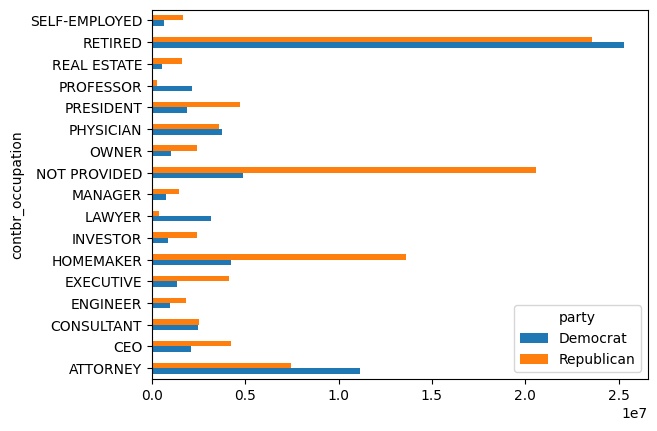

In [ ]:
# Vẽ biểu đồ ngang ('barh') từ DataFrame over_2mm
over_2mm.plot(kind="barh")

- Giải thích chi tiết:
    - over_2mm.plot(kind="barh"): Sử dụng phương thức plot của DataFrame với kiểu 'barh' (horizontal bar). Matplotlib sẽ tự động vẽ theo cột (Democrat và Republican).
    
    -Ý nghĩa: Dễ so sánh trực quan tổng đóng góp theo nghề và đảng.

- Nhận xét biểu đồ:
    - Biểu đồ ngang (barh) ở bước trước cho thấy tổng số tiền đóng góp theo nghề nghiệp cho hai đảng lớn (Democrat và Republican).
    - Một số nhận xét:
        - Nghề "RETIRED" đóng góp nhiều nhất cho cả hai đảng, cho thấy nhóm về hưu có ảnh hưởng lớn trong tài trợ chính trị.
        - "HOMEMAKER", "NOT PROVIDED", "ATTORNEY", "EXECUTIVE", "CEO" cũng là các nhóm đóng góp lớn.
        - Một số nghề như "ATTORNEY", "PROFESSOR", "LAWYER" có xu hướng đóng góp nhiều hơn cho Democrat.
        - Các nghề như "CEO", "EXECUTIVE", "OWNER", "PRESIDENT" lại đóng góp nhiều hơn cho Republican.
        - Sự khác biệt này phản ánh xu hướng chính trị theo nghề nghiệp, ví dụ: nhóm quản lý cấp cao, chủ doanh nghiệp thường nghiêng về phía đảng Cộng hòa, trong khi nhóm học thuật, luật sư, giáo viên lại nghiêng về phía Dân chủ.
        - Nghề "NOT PROVIDED" chiếm tỷ trọng lớn, cho thấy nhiều người không khai báo nghề nghiệp khi đóng góp.

### 10. Hàm Lấy Top Đóng Góp Và Áp Dụng
Tạo hàm để lấy top n đóng góp theo nhóm (nghề hoặc nhà tuyển dụng), áp dụng cho Obama & Romney.

In [ ]:
# Hàm tính tổng tiền theo key, lấy top n lớn nhất
def get_top_amounts(group, key, n=5):
    totals = group.groupby(key)["contb_receipt_amt"].sum()
    return totals.nlargest(n)

- Khai báo hàm có 3 tham số:

    - group:	Một DataFrame hoặc nhóm dữ liệu (thường lấy từ groupby)

    - key:	Tên cột muốn nhóm theo (ví dụ: nghề nghiệp, bang, thành phố, v.v.)

    - n=5:	Số lượng kết quả lớn nhất cần lấy (mặc định là 5)

    => có thể truyền vào bất kỳ cột nào làm key, không cố định.

- totals = group.groupby(key)["contb_receipt_amt"].sum()

    - Nhóm (groupby) dữ liệu theo cột key, rồi:

    - Lấy cột "contb_receipt_amt" (số tiền đóng góp).

    - Tính tổng (sum()) theo từng nhóm.

- return totals.nlargest(n)

    - .nlargest(n) là hàm của Pandas giúp lấy N giá trị lớn nhất trong Series.

    => Ở đây, nó sẽ trả về top n nghề hoặc nhóm có tổng tiền lớn nhất

In [ ]:
# Nhóm theo ứng cử viên
grouped = fec_mrbo.groupby("cand_nm")

In [ ]:
grouped.size() # Kiểm tra kích thước nhóm theo ứng cử viên

cand_nm
Obama, Barack    589127
Romney, Mitt     105155
dtype: int64

In [ ]:
# Áp dụng hàm cho nghề nghiệp, top 7
grouped.apply(get_top_amounts, "contbr_occupation", n=7) # Tính tổng đóng góp theo nghề nghiệp, lấy top 7 nghề có đóng góp cao nhất cho mỗi ứng cử viên

In [ ]:
# Áp dụng cho nhà tuyển dụng, top 10
grouped.apply(get_top_amounts, "contbr_employer", n=10) # Tính tổng đóng góp theo nhà tuyển dụng, lấy top 10 nhà tuyển dụng có đóng góp cao nhất cho mỗi ứng cử viên

- Giải thích chi tiết:

    - def get_top_amounts(...):: Hàm nhận group (DataFrame con), key (cột để nhóm), n (số lượng top).

    - group.groupby(key)["contb_receipt_amt"].sum(): Nhóm theo key, tính tổng tiền.
    - totals.nlargest(n): Lấy n giá trị lớn nhất từ Series.


    - fec_mrbo.groupby("cand_nm"): Nhóm DataFrame thành các subgroup theo ứng cử viên.
    - grouped.apply(...): Áp dụng hàm lên từng subgroup.
    -Ý nghĩa: Xem top nghề/nghề chủ đóng góp cho từng ứng cử viên.

### 11. Phân Loại Đóng Góp Theo Khoảng (Bucketing)
Sử dụng pd.cut để phân loại số tiền vào các khoảng, sau đó nhóm và tính toán.

In [ ]:
import numpy as np  # Import NumPy cho mảng

In [ ]:
# Mảng các khoảng (bins) để phân loại
bins = np.array([0, 1, 10, 100, 1000, 10000, 100_000, 1_000_000, 10_000_000])

- Tạo một mảng NumPy (np.array) chứa các giá trị mốc (cut-off points) để chia dữ liệu thành nhiều khoảng (bins).
- Ví dụ:
    - Mốc bắt đầu (từ 0 đô trở lên)
    - Từ 0 đến 1 đô
    - Từ 1 đến 10 đô
    - Từ 10 đến 100 đô
    *...*
    - Từ 1.000.000 đến 10.000.000 đô
    
-> Là bước khởi tạo các khoảng giá trị dùng để chia nhỏ dữ liệu (phân tầng) theo mức tiền đóng góp, giúp ta dễ dàng thống kê, so sánh và trực quan hóa dữ liệu sau này.

In [ ]:
# Phân loại số tiền vào bins, trả về categorical Series
labels = pd.cut(fec_mrbo["contb_receipt_amt"], bins)

- Hàm pd.cut() của pandas được dùng để phân chia dữ liệu số liên tục (continuous data) thành các khoảng (bins).

- Ở đây, ta đang phân loại (binning) cột contb_receipt_amt (số tiền đóng góp) trong DataFrame fec_mrbo
→ theo các khoảng giá trị đã được định nghĩa trong biến bins.

- Cách hoạt động:
    1. fec_mrbo["contb_receipt_amt"] lấy cột số tiền đóng góp của chỉ hai ứng cử viên Obama và Romney (vì ta đã lọc fec_mrbo từ trước).

    2. bins là mảng NumPy chứa các ranh giới phân loại: [0, 1, 10, 100, 1000, 10000, 100000, 1000000, 10000000].

    3. pd.cut() sẽ so sánh từng giá trị trong contb_receipt_amt và xác định xem giá trị đó thuộc vào khoảng nào.

    4. Kết quả trả về là một Series có cùng độ dài với fec_mrbo, nhưng mỗi dòng giờ đây là một khoảng (Interval) chứ không phải giá trị gốc.

=> Là bước phân loại (binning) các giá trị tiền đóng góp (contb_receipt_amt) vào những khoảng giá trị (bins) được xác định sẵn, giúp việc phân tích dữ liệu, thống kê và vẽ biểu đồ trở nên dễ dàng và trực quan hơn.

In [ ]:
# Hiển thị labels
labels

411         (10, 100]
412       (100, 1000]
413       (100, 1000]
414         (10, 100]
415         (10, 100]
             ...     
701381      (10, 100]
701382    (100, 1000]
701383        (1, 10]
701384      (10, 100]
701385    (100, 1000]
Name: contb_receipt_amt, Length: 694282, dtype: category
Categories (8, interval[int64, right]): [(0, 1] < (1, 10] < (10, 100] < (100, 1000] < (1000, 10000] < (10000, 100000] < (100000, 1000000] < (1000000, 10000000]]

- Giải thích chi tiết:
    - import numpy as np: Import NumPy để tạo mảng.

    - np.array([...]): Tạo mảng số cho các khoảng (ví dụ: (0,1], (1,10], ...).

    - pd.cut(..., bins): Phân loại từng giá trị trong Series thành khoảng, right=True (bao gồm giới hạn phải).
    
    -Ý nghĩa: Chuẩn bị cho histogram theo kích thước đóng góp.

In [ ]:
# Thống kê số lượng người quyên góp trong mỗi khoảng tiền:
labels.value_counts()

contb_receipt_amt
(10, 100]              404133
(100, 1000]            197348
(1000, 10000]           48470
(1, 10]                 43751
(0, 1]                    570
(1000000, 10000000]         4
(10000, 100000]             3
(100000, 1000000]           3
Name: count, dtype: int64

In [ ]:
# Tính tổng số tiền theo từng khoảng và đảng phái:
fec_mrbo.pivot_table("contb_receipt_amt", index=labels, columns="party", aggfunc="sum")

C:\Users\khoat\AppData\Local\Temp\ipykernel_10648\1119001536.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  fec_mrbo.pivot_table("contb_receipt_amt", index=labels, columns="party", aggfunc="sum")


party,Democrat,Republican
contb_receipt_amt,,
"(0, 1]",318.24,77.00
"(1, 10]",337267.62,29819.66
"(10, 100]",20288981.41,1987783.76
"(100, 1000]",54798531.46,22363381.69
"(1000, 10000]",51753705.67,63942145.42
"(10000, 100000]",59100.00,12700.00
"(100000, 1000000]",1490683.08,0.00
"(1000000, 10000000]",7148839.76,0.00


C:\Users\khoat\AppData\Local\Temp\ipykernel_10648\2809907480.py:5: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  fec_mrbo.pivot_table("contb_receipt_amt", index=labels, columns="party", aggfunc="sum").plot(kind="bar")


<Axes: xlabel='contb_receipt_amt'>

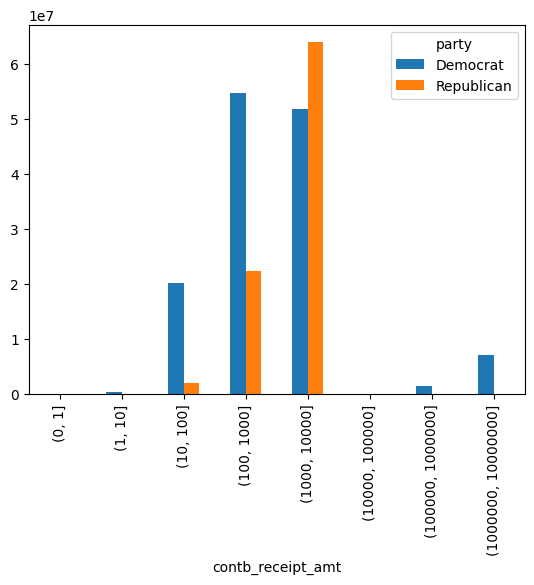

In [ ]:
# Vẽ biểu đồ thanh từ thống kê lượng người quyên góp trong mỗi khoảng tiền của mỗi đảng
fec_mrbo.pivot_table("contb_receipt_amt", index=labels, columns="party", aggfunc="sum").plot(kind="bar")

- Đầu tiên sẽ tạo một pivot_table từ cột quyên góp như đã làm ở các bước trên nhưng với index là label, sau đó sẽ biểu đồ dạng bar

- Nhận xét:
    - Đa số đóng góp cho cả Obama và Romney tập trung ở các khoảng nhỏ (10-100$, 100-1000$, 1000-10000$).
    - Obama nhận tỷ lệ lớn hơn ở các khoảng nhỏ (dưới 1000$), đặc biệt là dưới 100$.
    - Romney nhận tỷ lệ cao hơn ở các khoảng lớn (trên 1000$), nhất là 1000-10000$.
    - Các khoản đóng góp cực lớn (trên 100.000$) gần như chỉ dành cho Obama.
    - Điều này phản ánh: Obama có mạng lưới quyên góp rộng, nhiều người đóng góp nhỏ; Romney dựa nhiều hơn vào các khoản lớn từ ít người.
    - Biểu đồ giúp thấy rõ sự khác biệt về chiến lược gây quỹ giữa hai ứng viên.

### 12. Nhóm Và Tính Toán Theo Khoảng Đóng Góp
Nhóm theo ứng cử viên và khoảng, tính kích thước và tỷ lệ.

In [ ]:
# Nhóm theo ứng cử viên và labels
grouped = fec_mrbo.groupby(["cand_nm", labels])

C:\Users\khoat\AppData\Local\Temp\ipykernel_10648\903833411.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = fec_mrbo.groupby(["cand_nm", labels])


In [ ]:
# Đếm số lượng trong từng nhóm, unstack để thành bảng
grouped.size().unstack(level=0)

cand_nm,"Obama, Barack","Romney, Mitt"
contb_receipt_amt,,
"(0, 1]",493,77
"(1, 10]",40070,3681
"(10, 100]",372280,31853
"(100, 1000]",153991,43357
"(1000, 10000]",22284,26186
"(10000, 100000]",2,1
"(100000, 1000000]",3,0
"(1000000, 10000000]",4,0


In [ ]:
# Tính tổng tiền theo nhóm và unstack để thành bảng
bucket_sums = grouped["contb_receipt_amt"].sum().unstack(level=0)

In [ ]:
# Hiển thị tổng tiền theo nhóm
bucket_sums

cand_nm,"Obama, Barack","Romney, Mitt"
contb_receipt_amt,,
"(0, 1]",318.24,77.00
"(1, 10]",337267.62,29819.66
"(10, 100]",20288981.41,1987783.76
"(100, 1000]",54798531.46,22363381.69
"(1000, 10000]",51753705.67,63942145.42
"(10000, 100000]",59100.00,12700.00
"(100000, 1000000]",1490683.08,0.00
"(1000000, 10000000]",7148839.76,0.00


In [ ]:
# Chuẩn hóa bằng cách chia cho tổng theo hàng
normed_sums = bucket_sums.div(bucket_sums.sum(axis="columns"), axis="index")

- Mục tiêu: chuẩn hóa (normalize) theo hàng để biết tỷ lệ phần trăm mỗi ứng cử viên chiếm trong mỗi bin (khoảng).

- Giải thích:
    - bucket_sums.sum(axis="columns"): Tính tổng tiền của từng hàng (cộng tất cả các cột lại → tổng tiền trong mỗi khoảng).
    - .div(..., axis="index"); Dùng tổng hàng vừa tính để chia từng ô trong cùng hàng đó. Kết quả là mỗi ô = tỷ lệ phần trăm của tổng hàng.

In [ ]:
# Hiển thị
normed_sums

cand_nm,"Obama, Barack","Romney, Mitt"
contb_receipt_amt,,
"(0, 1]",0.805182,0.194818
"(1, 10]",0.918767,0.081233
"(10, 100]",0.910769,0.089231
"(100, 1000]",0.710176,0.289824
"(1000, 10000]",0.447326,0.552674
"(10000, 100000]",0.823120,0.176880
"(100000, 1000000]",1.000000,0.000000
"(1000000, 10000000]",1.000000,0.000000


In [ ]:
normed_sums * 100 # Hiển thị tỷ lệ phần trăm theo hàng

cand_nm,"Obama, Barack","Romney, Mitt"
contb_receipt_amt,,
"(0, 1]",80.518166,19.481834
"(1, 10]",91.876684,8.123316
"(10, 100]",91.076874,8.923126
"(100, 1000]",71.017590,28.982410
"(1000, 10000]",44.732551,55.267449
"(10000, 100000]",82.311978,17.688022
"(100000, 1000000]",100.000000,0.000000
"(1000000, 10000000]",100.000000,0.000000


<Axes: ylabel='contb_receipt_amt'>

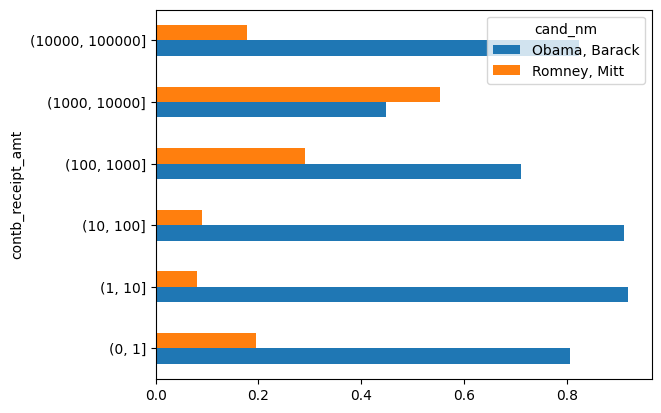

In [ ]:
# Vẽ biểu đồ ngang, loại bỏ 2 hàng cuối (lớn nhất, không phải từ cá nhân)
normed_sums[:-2].plot(kind="barh")

- Giải thích chi tiết:

    - fec_mrbo.groupby(["cand_nm", labels]): Nhóm đa cấp (ứng cử viên và khoảng).
    
    - grouped.size(): Đếm số dòng trong từng nhóm.

    - .unstack(level=0): Biến level 0 (cand_nm) thành cột.

    - grouped["contb_receipt_amt"].sum(): Tính tổng tiền thay vì đếm.

    - bucket_sums.div(..., axis="index"): Chia từng hàng cho tổng hàng (tỷ lệ %).

    - normed_sums[:-2].plot(kind="barh"): Vẽ, loại bỏ hàng lớn nhất.
    
    -Ý nghĩa: So sánh tỷ lệ đóng góp nhỏ/lớn giữa Obama và Romney.

### 13. Thống Kê Theo Tiểu Bang
Tổng hợp và tính tỷ lệ theo tiểu bang.

In [ ]:
# Nhóm theo ứng cử viên và tiểu bang
grouped = fec_mrbo.groupby(["cand_nm", "contbr_st"])

In [ ]:
grouped.size().unstack(level=0) # Đếm số lượng trong từng nhóm, unstack để thành bảng

cand_nm,"Obama, Barack","Romney, Mitt"
contbr_st,,
AA,74.0,2.0
AB,4.0,NaN
AE,395.0,16.0
AK,2036.0,284.0
AL,3854.0,804.0
...,...,...
WI,8050.0,713.0
WV,1330.0,201.0
WY,1055.0,380.0


In [ ]:
# Tính tổng tiền, unstack, điền NaN bằng 0
totals = grouped["contb_receipt_amt"].sum().unstack(level=0).fillna(0)

In [ ]:
totals # Hiển thị tổng tiền theo tiểu bang và ứng cử viên sau khi xử lý

cand_nm,"Obama, Barack","Romney, Mitt"
contbr_st,,
AA,56405.00,135.00
AB,2048.00,0.00
AE,42973.75,5680.00
AK,281840.15,86204.24
AL,543123.48,527303.51
...,...,...
WI,1130155.46,270316.32
WV,169154.47,126725.12
WY,194046.74,252595.84


In [ ]:
# Lọc tiểu bang có tổng > 100.000
totals = totals[totals.sum(axis="columns") > 100000]

In [ ]:
# Hiển thị thông tin của totals
totals.info()

<class 'pandas.core.frame.DataFrame'>
Index: 52 entries, AK to XX
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Obama, Barack  52 non-null     float64
 1   Romney, Mitt   52 non-null     float64
dtypes: float64(2)
memory usage: 1.2+ KB


In [ ]:
# Hiển thị 10 dòng đầu tiên
totals.head(10)

cand_nm,"Obama, Barack","Romney, Mitt"
contbr_st,,
AK,281840.15,86204.24
AL,543123.48,527303.51
AR,359247.28,105556.00
AZ,1506476.98,1888436.23
CA,23824984.24,11237636.60
CO,2132429.49,1506714.12
CT,2068291.26,3499475.45
DC,4373538.80,1025137.50
DE,336669.14,82712.00


- Giải thích chi tiết:
    - groupby(["cand_nm", "contbr_st"]): Nhóm theo hai cột.

    - .sum().unstack(level=0): Tính tổng, biến cand_nm thành cột.

    - .fillna(0): Thay NaN bằng 0.

    - totals.sum(axis="columns") > 100000: Lọc hàng.
    
    -Ý nghĩa: Xem tiểu bang nào đóng góp lớn trên 100000

### 14. Tính Tỷ Lệ Phần Trăm Theo Tiểu Bang

In [ ]:
# Chia từng hàng cho tổng hàng để lấy %
percent = totals.div(totals.sum(axis="columns"), axis="index")

In [ ]:
# Hiển thị 10 dòng đầu tiên của percent
percent.head(10)

cand_nm,"Obama, Barack","Romney, Mitt"
contbr_st,,
AK,0.765778,0.234222
AL,0.507390,0.492610
AR,0.772902,0.227098
AZ,0.443745,0.556255
CA,0.679498,0.320502
CO,0.585970,0.414030
CT,0.371476,0.628524
DC,0.810113,0.189887
DE,0.802776,0.197224


In [ ]:
percent.sort_values(by="Obama, Barack", ascending=False) # Sắp xếp theo cột Obama

cand_nm,"Obama, Barack","Romney, Mitt"
contbr_st,,
VT,0.946983,0.053017
ME,0.908825,0.091175
PR,0.881192,0.118808
HI,0.876774,0.123226
MN,0.855913,0.144087
NM,0.843590,0.156410
IL,0.819226,0.180774
DC,0.810113,0.189887
WI,0.806982,0.193018


- Giải thích
    - .sort_values()	Hàm dùng để sắp xếp các hàng của DataFrame.
    - by="Obama, Barack"	Tức là sắp xếp theo giá trị trong cột “Obama, Barack”.
    - ascending=False	Nghĩa là sắp xếp giảm dần (từ lớn đến nhỏ). Nếu để True, nó sẽ sắp tăng dần (từ nhỏ đến lớn).

In [ ]:
percent.sort_values(by="Romney, Mitt", ascending=False).head(10) # Sắp xếp theo cột Romney và in ra top 10 bang có tỷ lệ đóng góp cao nhất cho Romney

cand_nm,"Obama, Barack","Romney, Mitt"
contbr_st,,
XX,0.000000,1.000000
UT,0.122689,0.877311
ID,0.200608,0.799392
SD,0.341899,0.658101
LA,0.356026,0.643974
CT,0.371476,0.628524
MS,0.371535,0.628465
OK,0.414515,0.585485
TN,0.424589,0.575411


- Giải thích chi tiết:
    - totals.div(..., axis="index"): Tương tự phần trước, tính tỷ lệ % cho từng ứng cử viên theo tiểu bang.
    
    -Ý nghĩa: Xem Obama hay Romney nhận nhiều hơn ở từng bang.

### Kết Luận
- Notebook này đã đi qua toàn bộ quy trình phân tích dữ liệu FEC 2012: từ tải dữ liệu, làm sạch, thêm thông tin đảng phái, đến các phân tích thống kê và trực quan hóa. Các công cụ chính là Pandas (cho DataFrame, groupby, pivot), NumPy (cho bins), và Matplotlib (cho plot).

## Kết thúc